# Инженерия признаков на датасете Online Shoppers Purchasing Intention

**Дисциплина:** Машинное обучение и ИИ   
**Модуль 4:** Инженерия признаков и работа с нестандартными данными   
**Датасет:** Online Shoppers Purchasing Intention Dataset   

Выполнила: Жданова Анна Александровна   
Группа: ПКТб-23-1   
Преподаватель: Спирин И.С.

Ссылка на репозиторий: https://github.com/ZhdanovaAnna/ml-course-zhdanova

Путь к модулю: module-4-features/notebook.ipynb

Дата: 30.10.2026

## 2. Введение

**Какую задачу решаем?**  
Решаем задачу бинарной классификации: по характеристикам сессии посетителя интернет-магазина предсказываем, завершится ли она покупкой (`Revenue = 1`) или нет (`Revenue = 0`).

**Что такое инженерия признаков?**  
Инженерия признаков - это процесс преобразования исходных данных и создания на их основе новых признаков, которые лучше описывают поведение пользователей. Например, можно объединить время на разных типах страниц в общее время сессии или рассчитать отношение показателя отказов к показателю выхода. Такие признаки могут помочь модели выявить закономерности, связанные с покупкой.

**Почему для IT-компании важно прогнозировать покупку?**  
Прогноз помогает оценивать вероятность конверсии, находить перспективные сессии и эффективнее распределять маркетинговый бюджет. На его основе компания может улучшать персонализацию предложений, пользовательский путь и работу сайта, повышая вероятность покупки и снижая затраты на привлечение клиентов.

**Какая метрика важнее в этой задаче?**  
Одной Accuracy недостаточно: при дисбалансе классов модель может часто предсказывать отсутствие покупки и при этом иметь относительно высокую Accuracy. F1 учитывает баланс Precision и Recall, а ROC-AUC оценивает способность модели различать сессии с покупкой и без покупки при разных порогах. В этой работе основной метрикой сравнения выбрана **ROC-AUC**, а F1 и Recall используются дополнительно для оценки качества обнаружения покупок.

**Цель работы**  
   1) Создать 5+ новых признаков на основе поведения пользователя.

   2) Обучить 4 ансамблевые модели и сравнить их.

   3) Интерпретировать лучшую модель через SHAP.

**Объект исследования:** сессии посетителей интернет-магазина.  

**Целевая переменная:** `Revenue` - совершена ли покупка в рамках сессии.

## 3. Теоретическая часть

**Feature Engineering** - систематическое преобразование исходных данных и создание новых признаков, которые помогают модели обнаруживать закономерности. Признаки должны быть содержательно обоснованы, воспроизводимы и доступны на момент прогноза. Важное ограничение - не использовать сведения, которые становятся известны только после целевого события, иначе возникает утечка данных.

| Метод/понятие | Суть | Применение |
|---|---|---|
| Агрегация | Суммирование или усреднение нескольких полей | Общее число страниц и суммарное время сессии |
| Отношения | Сопоставление величин с защитой от деления на ноль | Соотношение показателей отказов и выходов |
| Бинаризация | Перевод условия в 0/1 | Новый посетитель, выходной день |
| Временные признаки | Выделение месяца, дня недели или периода | Месяц сессии, близость особого дня |
| One-Hot Encoding | Отдельный бинарный столбец для каждой категории | `VisitorType`, `Month`, браузер |
| TF-IDF | Вес слова с учётом частоты и редкости в коллекции | Текстовые отзывы и описания |
| Haversine | Географическое расстояние по координатам | Расстояние до ресторана или склада |
| DBSCAN | Кластеризация по плотности, включая поиск выбросов | Поиск групп похожих пространственных точек |
| Лаги и скользящие окна | Использование предыдущих значений и агрегатов за период | Прогноз спроса по временным рядам |

В данной работе основное внимание уделяется агрегатам, отношениям и категориальным признакам. TF-IDF, Haversine, DBSCAN, лаги и скользящие окна рассматриваются теоретически: в выбранном датасете нет текстовых документов, географических координат и последовательности повторных наблюдений, необходимой для полноценного применения этих методов.

Формулы:

$$TotalPages = Administrative + Informational + ProductRelated$$

$$TotalDuration = Administrative\_Duration + Informational\_Duration + ProductRelated\_Duration$$

$$PageShare = \frac{ProductRelated}{TotalPages + \epsilon}$$

Малая константа $\epsilon$ нужна, чтобы избежать деления на ноль.

Инженерия признаков связывает техническую обработку данных с предметной областью. Для поведения покупателей особенно полезны показатели глубины просмотра, длительности и структуры сессии; при этом все преобразования должны рассчитываться одинаково при обучении и использовании модели.

**Схема исследования**
|Этап |	Содержание | Результат|
|-----|------------|----------|
|1	|Загрузка данных|	Исходная таблица Online Shoppers Purchasing Intention|
|2	|EDA	|Понимание структуры данных и зависимостей между признаками|
|3	|Предобработка|	Очищенные и подготовленные признаки|
|4	|Feature Engineering	|Создание дополнительных признаков|
|5	|Обучение	|Четыре ансамблевые модели: Random Forest, XGBoost, LightGBM, CatBoost|
|6	|Оценка	|Сравнительная таблица метрик Accuracy, Precision, Recall, F1-score и ROC-AUC|
|7	|Оптимизация	|Настройка гиперпараметров с помощью Optuna|
|8	|Интерпретация|	Анализ важности признаков и объяснение предсказаний с помощью SHAP|
|9	|Сохранение	|Файлы обученных моделей и метаданные|
|10	|Проверка загрузки|	Возможность повторного использования сохранённых моделей|

## 4. Описание данных

Используется **Online Shoppers Purchasing Intention Dataset** из UCI Machine Learning Repository. Набор описывает сессии посетителей интернет-магазина и содержит числовые поведенческие показатели, категориальные характеристики и целевую переменную `Revenue`.

1) Ожидаемый размер исходного набора - 12 330 строк и 18 столбцов.

2) Входные признаки описывают посещения административных, информационных и товарных страниц, длительность просмотра, показатели отказов и выхода, месяц, тип посетителя, устройство/браузер и источник трафика.

3) `Revenue` показывает, завершилась ли сессия покупкой. Это целевой столбец, он не должен попадать в `X`.

4) Задача - бинарная классификация; классы несбалансированы, так как покупка встречается реже, чем отсутствие покупки.

Источник: [UCI Machine Learning Repository - Online Shoppers Purchasing Intention Dataset](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset).

**Путь к файлу:** `data/online_shoppers_intention.csv`. 

In [1]:
# Импортируем библиотеки для загрузки, анализа, визуализации и моделирования
from pathlib import Path                                   
import time                               
import json                                 
import warnings                                                
warnings.filterwarnings("ignore")                                                                   

import numpy as np                         
import pandas as pd                     
import matplotlib.pyplot as plt                        
import seaborn as sns                                

RANDOM_STATE = 42                                         
DATA_DIR = Path("data")                                          
MODEL_DIR = Path("models")                                           
EXAMPLES_DIR = Path("examples")                       
DATA_DIR.mkdir(parents=True, exist_ok=True)                                           
MODEL_DIR.mkdir(parents=True, exist_ok=True)                                            
EXAMPLES_DIR.mkdir(parents=True, exist_ok=True)                                                         

In [2]:
# Загрузка датасета и описнаие данных
data_path = DATA_DIR / "online_shoppers_intention.csv"                                       

df = pd.read_csv(data_path)                               

# Проверка пропусков и нулевых значений
print(f"Размер датасета: {df.shape[0]} строк × {df.shape[1]} столбцов")   
print("Количество пропусков:", df.isna().sum().sum())
print("\nКоличество дубликатов:", df.duplicated().sum())

zero_counts = (df == 0).sum().sort_values(ascending=False)
print("\nКоличество нулевых значений по столбцам:")
display(zero_counts.to_frame("Количество нулей"))

display(df.head())                             
display(df.dtypes.rename("Тип данных").to_frame())                            
print("\nПропуски по столбцам:")                               
display(df.isna().sum().sort_values(ascending=False).rename("Количество пропусков").to_frame())                       
print("\nРаспределение Revenue:")                                    
display(pd.DataFrame({"Количество": df["Revenue"].value_counts(), "Доля": df["Revenue"].value_counts(normalize=True).round(4)}))               

Размер датасета: 12330 строк × 18 столбцов
Количество пропусков: 0

Количество дубликатов: 125

Количество нулевых значений по столбцам:


,Количество нулей
SpecialDay,11079
Revenue,10422
Informational_Duration,9925
Informational,9699
PageValues,9600
Weekend,9462
Administrative_Duration,5903
Administrative,5768
BounceRates,5518
ProductRelated_Duration,755


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


,Тип данных
Administrative,int64
Administrative_Duration,float64
Informational,int64
Informational_Duration,float64
ProductRelated,int64
ProductRelated_Duration,float64
BounceRates,float64
ExitRates,float64
PageValues,float64
SpecialDay,float64



Пропуски по столбцам:


,Количество пропусков
Administrative,0
Administrative_Duration,0
Informational,0
Informational_Duration,0
ProductRelated,0
ProductRelated_Duration,0
BounceRates,0
ExitRates,0
PageValues,0
SpecialDay,0



Распределение Revenue:


,Количество,Доля
Revenue,,
False,10422,0.8453
True,1908,0.1547


**Вывод по разделу.** Данные загружены из указанного локального файла. 

Сводка подтверждает фактический размер таблицы, типы столбцов, наличие пропусков и распределение `Revenue`; эти значения следует использовать в дальнейшем анализе.

## 5. Подготовка данных и EDA

Сначала проверяются размер таблицы, типы полей, пропуски, дубликаты и баланс классов. Точные дубликаты удаляются, поскольку они могут приводить к завышенной оценке качества, если одинаковые записи окажутся в разных выборках. Пропуски заполняются медианой для числовых полей и наиболее частым значением для категориальных.

Для EDA предусмотрены графики распределения `Revenue`, длительности сессии, `PageValues`, поведения по типу посетителя, месяца и выходного дня, а также корреляционная матрица. В совокупности они помогают заметить дисбаланс, асимметрии распределений и возможные связи с покупкой.

Создаются новые признаки:
1) `TotalPages` - общее количество просмотренных страниц;

2) `TotalDuration`- суммарное время на трёх типах страниц;

3) `AvgPageValue` - нормализованная ценность страницы относительно глубины сессии;

4) `BounceExitRatio` - отношение BounceRates к ExitRates с защитой от нуля;

5) `IsNewVisitor` - индикатор нового посетителя;

6) `IsWeekend` - выходной день в числовом виде;

7) `MonthNum` - числовое представление месяца;

8) `IsHighTraffic` - индикатор высокого кода источника трафика.

Часть признаков является преобразованием исходных полей, а не дополнительной информацией извне. Это полезно для проверки гипотез о поведении, но фактическая ценность каждого признака должна подтверждаться метриками и интерпретацией модели.

Полных дубликатов: 125
Размер после очистки: (12205, 26)
Число признаков после Feature Engineering (без Revenue): 25


,count,mean,std,min,25%,50%,75%,max
TotalPages,12205.0,34.893240,46.627336,0.0,9.000000,20.000000,42.000000,746.000000
TotalDuration,12205.0,1323.454242,2043.871589,0.0,231.666667,690.958333,1643.958333,69921.647230
AvgPageValue,12205.0,0.261739,1.212627,0.0,0.000000,0.000000,0.000000,33.848087
BounceExitRatio,12205.0,0.275324,0.334693,0.0,0.000000,0.154044,0.487805,3.626220
IsNewVisitor,12205.0,0.138714,0.345662,0.0,0.000000,0.000000,0.000000,1.000000
MonthNum,12205.0,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000
IsHighTraffic,12205.0,0.102417,0.303208,0.0,0.000000,0.000000,0.000000,1.000000


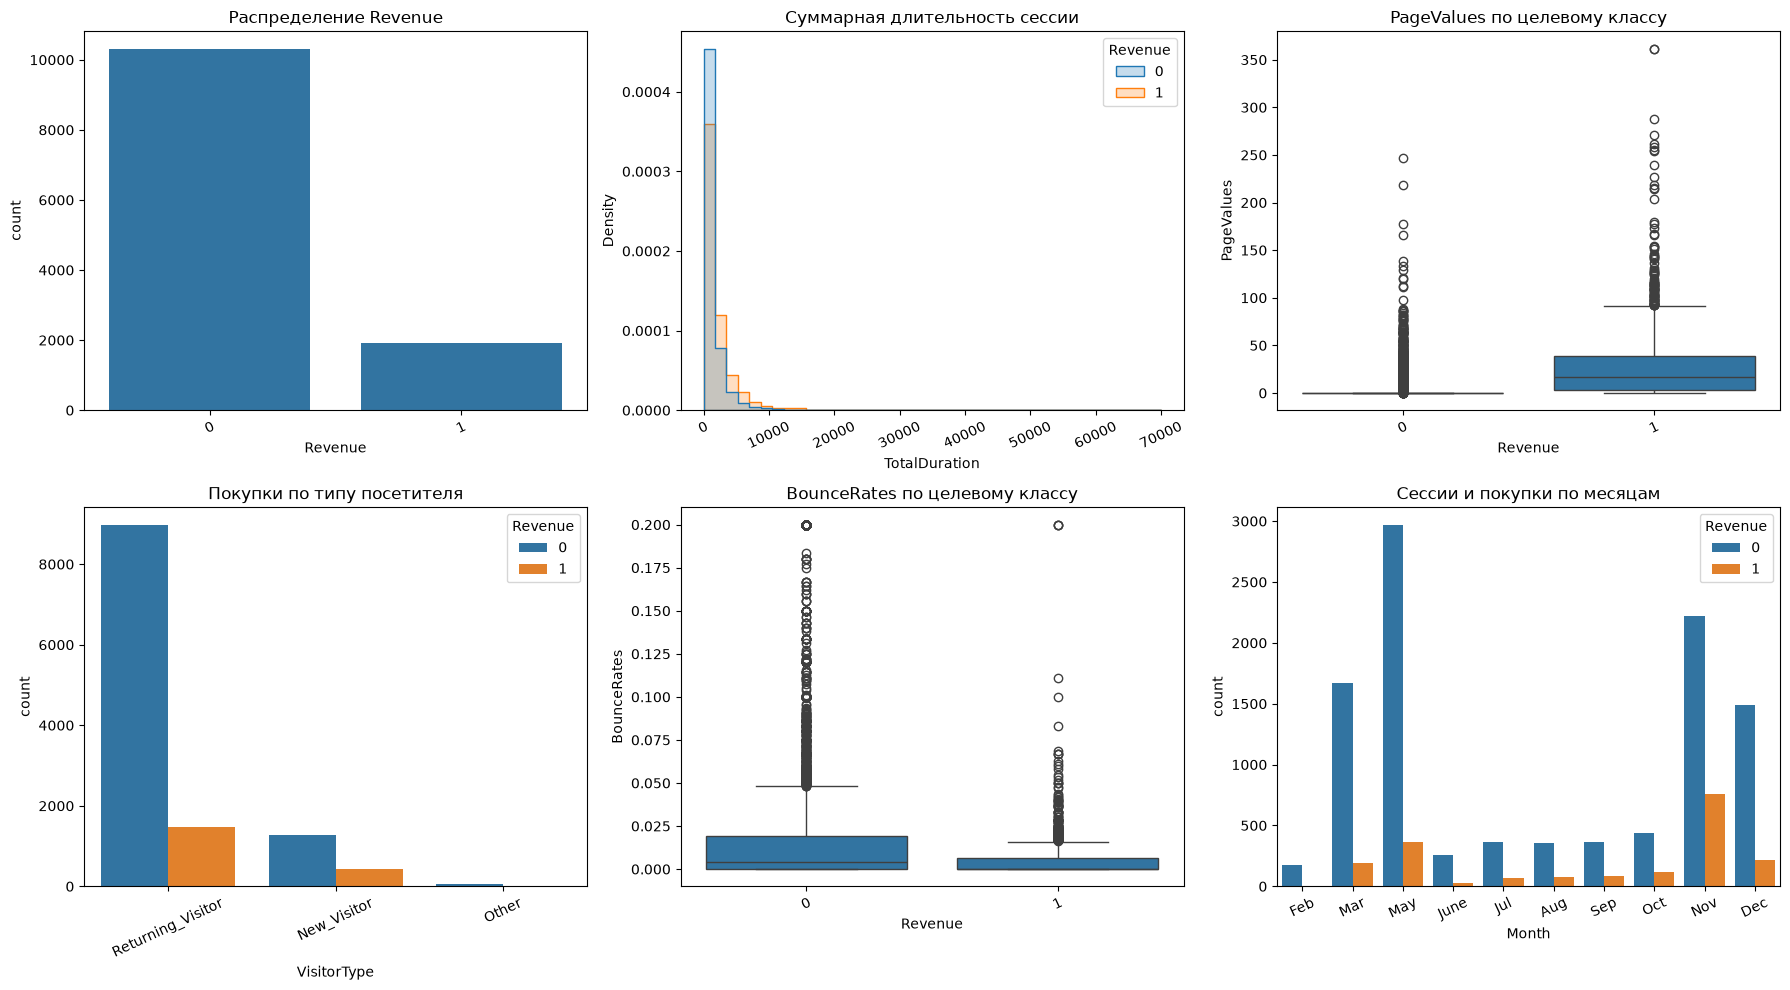

In [3]:
# Приводим целевую переменную к 0/1 и проверяем повторы до дальнейших преобразований
df["Revenue"] = df["Revenue"].astype(int)                                                 
duplicate_count = int(df.duplicated().sum())                             
print(f"Полных дубликатов: {duplicate_count}")                             
df = df.drop_duplicates().copy()                                                                     

# Заполняем пропуски консервативно: числовые  медианой, категориальные - модой
for col in df.columns:                                         
    if df[col].isna().any():                                             
        if pd.api.types.is_numeric_dtype(df[col]):                            
            df[col] = df[col].fillna(df[col].median())                                         
        else:                                                                  
            df[col] = df[col].fillna(df[col].mode(dropna=True).iloc[0])                             

# Создаём агрегаты сессии, отражающие глубину просмотра и вовлечённость
df["TotalPages"] = df["Administrative"] + df["Informational"] + df["ProductRelated"]                        
df["TotalDuration"] = df["Administrative_Duration"] + df["Informational_Duration"] + df["ProductRelated_Duration"]                           
df["AvgPageValue"] = df["PageValues"] / (df["TotalPages"] + 1)                                                         
df["BounceExitRatio"] = df["BounceRates"] / (df["ExitRates"] + 0.001)                                                  
df["IsNewVisitor"] = (df["VisitorType"] == "New_Visitor").astype(int)                                
df["IsWeekend"] = df["Weekend"].astype(int)                                     
df["MonthNum"] = pd.to_datetime(df["Month"], format="%b", errors="coerce").dt.month                                        
df["MonthNum"] = df["MonthNum"].fillna(0).astype(int)                                                          
df["IsHighTraffic"] = (df["TrafficType"] > 10).astype(int)                                                     

# Печатаем краткую статистику, чтобы результаты можно было перенести в отчёт
print(f"Размер после очистки: {df.shape}")                                               
print(f"Число признаков после Feature Engineering (без Revenue): {df.drop(columns='Revenue').shape[1]}")                             
display(df[["TotalPages", "TotalDuration", "AvgPageValue", "BounceExitRatio", "IsNewVisitor", "MonthNum", "IsHighTraffic"]].describe().T)                                            

# Строим сетку из шести подписанных графиков EDA
fig, axes = plt.subplots(2, 3, figsize=(18, 10))                      
sns.countplot(data=df, x="Revenue", ax=axes[0, 0])                                      
axes[0, 0].set_title("Распределение Revenue")                              
sns.histplot(data=df, x="TotalDuration", hue="Revenue", bins=40, element="step", stat="density", common_norm=False, ax=axes[0, 1])                                              
axes[0, 1].set_title("Суммарная длительность сессии")                              
sns.boxplot(data=df, x="Revenue", y="PageValues", ax=axes[0, 2])                                         
axes[0, 2].set_title("PageValues по целевому классу")                              
sns.countplot(data=df, x="VisitorType", hue="Revenue", ax=axes[1, 0])                                            
axes[1, 0].set_title("Покупки по типу посетителя")                                 
sns.boxplot(data=df, x="Revenue", y="BounceRates", ax=axes[1, 1])                                  
axes[1, 1].set_title("BounceRates по целевому классу")                             
month_order = ["Feb", "Mar", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]                                                       
sns.countplot(data=df, x="Month", hue="Revenue", order=[m for m in month_order if m in set(df["Month"])], ax=axes[1, 2])                                               
axes[1, 2].set_title("Сессии и покупки по месяцам")                              
for ax in axes.flat:                              
    ax.set_xlabel(ax.get_xlabel() or "Значение")                                
    ax.set_ylabel(ax.get_ylabel() or "Количество")                                
    ax.tick_params(axis="x", rotation=25)                                        
plt.tight_layout()                                
plt.savefig(EXAMPLES_DIR / "eda_plots.png", dpi=150, bbox_inches="tight")                          
plt.show()                            

**Вывод по разделу.** После проверки удаляются точные дубликаты и обрабатываются обнаруженные пропуски. Добавлено более пяти новых поведенческих признаков, а графики позволяют сравнить структуру сессий и целевой класс. По распределению `Revenue` видно, насколько выражен дисбаланс, который учитывается при обучении.

## 6. Построение и обучение моделей

Данные разделяются на обучающую и тестовую выборки в пропорции 80/20 с сохранением доли покупок в обеих частях (`stratify=y`). 

Кодирование категорий обучается только на тренировочной выборке. Это важно: если заранее изучить категории или статистики всей таблицы, информация о тестовой выборке может попасть в процесс подготовки.

Сравниваются четыре ансамбля:
1) **Random Forest** усредняет предсказания множества деревьев и обычно служит устойчивой базовой моделью;

2) **XGBoost** использует градиентный бустинг и регуляризацию;

3) **LightGBM** ориентирован на эффективное обучение градиентного бустинга на табличных данных;

4) **CatBoost** также реализует градиентный бустинг и изначально разработан с сильной поддержкой категориальных данных. В этой работе все модели получают одинаковое One-Hot-представление для сопоставимости.

Из-за дисбаланса классов применяются веса классов или параметр веса положительного класса. Для каждой модели фиксируются метрики и время обучения.

In [4]:
# Импортируем алгоритмы и инструменты разделения данных
from sklearn.model_selection import train_test_split                                             
from sklearn.preprocessing import OneHotEncoder                                         
from sklearn.compose import ColumnTransformer                                         
from sklearn.pipeline import Pipeline                                        
from sklearn.impute import SimpleImputer                                    
from sklearn.ensemble import RandomForestClassifier                     
from xgboost import XGBClassifier                                
from lightgbm import LGBMClassifier                                 
from catboost import CatBoostClassifier                                 

# Разделяем признаки и целевую переменную; Revenue не попадает во входные данные
X = df.drop(columns=["Revenue"]).copy()                                           
y = df["Revenue"].astype(int).copy()                          
categorical_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()                                      
numeric_cols = [col for col in X.columns if col not in categorical_cols]                                        
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)                                           

# Обучаем преобразователь только на train, чтобы не подглядывать в тестовую выборку
try:                                                  
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)                                          
except TypeError:                                                                 
    encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)                                     
preprocessor = ColumnTransformer([("cat", encoder, categorical_cols), ("num", SimpleImputer(strategy="median"), numeric_cols)], remainder="drop", verbose_feature_names_out=False)                                     
X_train_enc = preprocessor.fit_transform(X_train)                                                      
X_test_enc = preprocessor.transform(X_test)                                                  
feature_cols = preprocessor.get_feature_names_out().tolist()                                                       
X_train_enc = pd.DataFrame(X_train_enc, columns=feature_cols, index=X_train.index)                                                
X_test_enc = pd.DataFrame(X_test_enc, columns=feature_cols, index=X_test.index)                                        

# Считаем вес положительного класса из train, а не задаём его вручную
negative_count = int((y_train == 0).sum())                                     
positive_count = int((y_train == 1).sum())                                    
positive_weight = negative_count / max(positive_count, 1)                                  

models = {                                                             
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=10, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),                             
    "XGBoost": XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1, subsample=0.9, colsample_bytree=0.9, scale_pos_weight=positive_weight, random_state=RANDOM_STATE, eval_metric="logloss", n_jobs=-1),                                       
    "LightGBM": LGBMClassifier(n_estimators=200, num_leaves=31, max_depth=7, learning_rate=0.05, class_weight="balanced", random_state=RANDOM_STATE, verbosity=-1, n_jobs=-1),                                     
    "CatBoost": CatBoostClassifier(iterations=200, depth=6, learning_rate=0.1, auto_class_weights="Balanced", random_seed=RANDOM_STATE, verbose=False, thread_count=-1)                                              
}
training_times = {}                                 
for name, model in models.items():                              
    start_time = time.time()                              
    model.fit(X_train_enc, y_train)                                                        
    training_times[name] = time.time() - start_time                                    
    print(f"{name}: время обучения {training_times[name]:.3f} сек.")                           

Random Forest: время обучения 1.175 сек.
XGBoost: время обучения 1.386 сек.
LightGBM: время обучения 0.328 сек.
CatBoost: время обучения 1.888 сек.


**Вывод по разделу.** Четыре ансамбля обучены на одинаковом стратифицированном разбиении. 

Результат позволяет сравнить качество и время обучения; окончательный лидер определяется по фактическим ROC-AUC и дополнительным метрикам, а не заранее.

## 7. Оценка качества

Модели сравниваются по пяти метрикам. **Accuracy** - доля правильных ответов; **Precision** - насколько надёжны предсказания покупки; **Recall** - какая доля реальных покупок найдена; **F1** - гармоническое среднее Precision и Recall; **ROC-AUC** - качество ранжирования сессий по вероятности покупки.

Из-за дисбаланса Accuracy не используется как единственный критерий. 

Для бизнеса высокий Recall может быть важен, если дорого пропустить потенциального покупателя, а высокий Precision - если дорого отправлять скидку тем, кто и так не собирался покупать. ROC-AUC удобно использовать для сравнения моделей до выбора рабочего порога.

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,"Training time, sec"
0,Random Forest,0.8746,0.5676,0.8351,0.6758,0.9328,1.1746
1,CatBoost,0.8755,0.5722,0.8089,0.6703,0.9319,1.8877
2,LightGBM,0.8730,0.5674,0.7932,0.6616,0.9312,0.3279
3,XGBoost,0.8849,0.6054,0.7592,0.6736,0.9310,1.3862


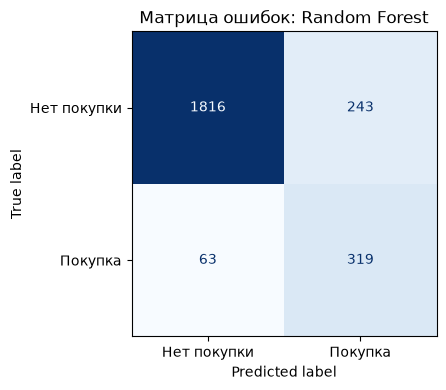

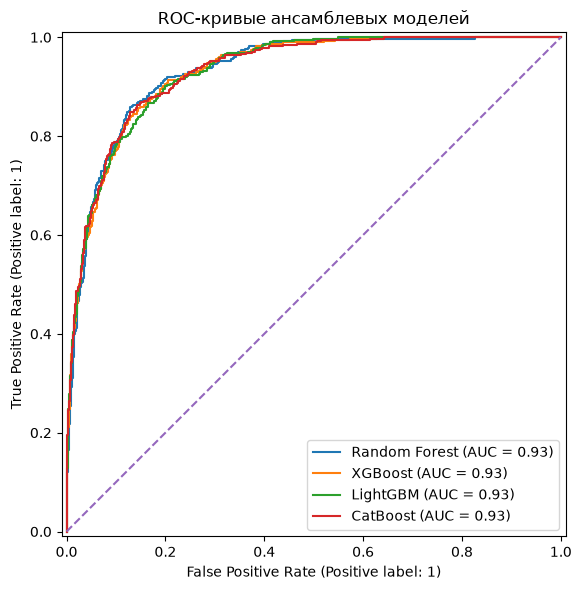

Лучшая baseline-модель по ROC-AUC: Random Forest
              precision    recall  f1-score   support

 Нет покупки       0.97      0.88      0.92      2059
     Покупка       0.57      0.84      0.68       382

    accuracy                           0.87      2441
   macro avg       0.77      0.86      0.80      2441
weighted avg       0.90      0.87      0.88      2441



In [5]:
# Импортируем метрики и инструменты визуализации качества
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report, RocCurveDisplay                          
from sklearn.metrics import ConfusionMatrixDisplay                               

def evaluate_model(model, X_eval, y_eval, name):                                 
    y_pred = model.predict(X_eval)                                    
    y_proba = model.predict_proba(X_eval)[:, 1]                                               
    return {"Model": name, "Accuracy": accuracy_score(y_eval, y_pred), "Precision": precision_score(y_eval, y_pred, zero_division=0), "Recall": recall_score(y_eval, y_pred, zero_division=0), "F1": f1_score(y_eval, y_pred, zero_division=0), "ROC-AUC": roc_auc_score(y_eval, y_proba)}                                        

results = [evaluate_model(model, X_test_enc, y_test, name) for name, model in models.items()]                                          
results_df = pd.DataFrame(results).sort_values("ROC-AUC", ascending=False).reset_index(drop=True)                         
results_df["Training time, sec"] = results_df["Model"].map(training_times)                                       
display(results_df.round(4))                                        

best_baseline_name = results_df.iloc[0]["Model"]                                               
best_baseline = models[best_baseline_name]                                  
best_pred = best_baseline.predict(X_test_enc)                                            
fig, ax = plt.subplots(figsize=(5, 4))                                       
ConfusionMatrixDisplay.from_predictions(y_test, best_pred, display_labels=["Нет покупки", "Покупка"], cmap="Blues", ax=ax, colorbar=False)                                                 
ax.set_title(f"Матрица ошибок: {best_baseline_name}")                        
plt.tight_layout()                                   
plt.show()                              

fig, ax = plt.subplots(figsize=(8, 6))                               
for name, model in models.items():                                           
    RocCurveDisplay.from_estimator(model, X_test_enc, y_test, name=name, ax=ax)                            
ax.plot([0, 1], [0, 1], linestyle="--", label="Случайный классификатор")                                    
ax.set_title("ROC-кривые ансамблевых моделей")                       
plt.tight_layout()                     
plt.savefig(EXAMPLES_DIR / "roc_curves.png", dpi=150, bbox_inches="tight")                         
plt.show()                          

print(f"Лучшая baseline-модель по ROC-AUC: {best_baseline_name}")                                   
print(classification_report(y_test, best_pred, target_names=["Нет покупки", "Покупка"], zero_division=0))                                          

**Вывод по разделу.** ROC-кривые и матрицы ошибок показывают разные стороны качества: ранжирование, найденные покупки и ошибочные срабатывания. 

При выборе модели нужно учитывать не только Accuracy, но и баланс Precision/Recall.

## 8. Интерпретация и бизнес-инсайты

Важность признаков рассчитывается для Random Forest и LightGBM после кодирования. У деревьев она отражает, насколько часто и насколько полезно признак использовался при разбиениях, но не является доказательством причинности. Коррелирующие признаки могут делить важность между собой.

С точки зрения e-commerce полезно проверить, насколько значимы показатели ценности страницы, товарной активности, длительности сессии, отказов и типа посетителя. 

15 признаков: Random Forest


,Feature,Importance
31,AvgPageValue,0.30327
23,PageValues,0.26746
22,ExitRates,0.05619
30,TotalDuration,0.04111
20,ProductRelated_Duration,0.04050
7,Month_Nov,0.03681
19,ProductRelated,0.03183
29,TotalPages,0.02776
21,BounceRates,0.02555
16,Administrative_Duration,0.02486


15 признаков: LightGBM


,Feature,Importance
22,ExitRates,760
16,Administrative_Duration,423
20,ProductRelated_Duration,394
30,TotalDuration,371
19,ProductRelated,360
29,TotalPages,347
31,AvgPageValue,310
23,PageValues,299
32,BounceExitRatio,296
28,TrafficType,287


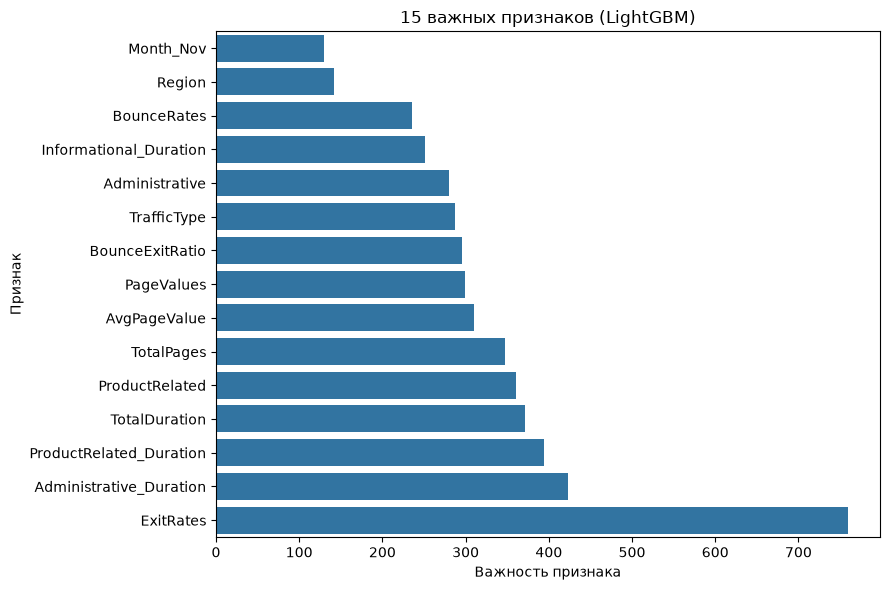

5 признаков LightGBM: ExitRates, Administrative_Duration, ProductRelated_Duration, TotalDuration, ProductRelated
Бизнес-интерпретация: использовать эти признаки для анализа вовлечённости и сегментации сессий; направление влияния проверить SHAP-графиками.


In [6]:
# Строим таблицы важности для Random Forest и LightGBM
importance_tables = {}                                                
for model_name in ["Random Forest", "LightGBM"]:                                                              
    importance_tables[model_name] = pd.DataFrame({"Feature": feature_cols, "Importance": models[model_name].feature_importances_}).sort_values("Importance", ascending=False)                                           
    print(f"15 признаков: {model_name}")                               
    display(importance_tables[model_name].head(15).round(5))                                                 

# Визуализируем важность LightGBM и сохраняем график
top_lgbm = importance_tables["LightGBM"].head(15).sort_values("Importance", ascending=True)                                           
fig, ax = plt.subplots(figsize=(9, 6))                   
sns.barplot(data=top_lgbm, x="Importance", y="Feature", ax=ax)                              
ax.set_title("15 важных признаков (LightGBM)")                       
ax.set_xlabel("Важность признака")                      
ax.set_ylabel("Признак")                      
plt.tight_layout()                     
plt.savefig(EXAMPLES_DIR / "feature_importance.png", dpi=150, bbox_inches="tight")                              
plt.show()                      

# Формируем нейтральные бизнес-инсайты на основании полученного ранжирования
top5_features = importance_tables["LightGBM"]["Feature"].head(5).tolist()                                         
print("5 признаков LightGBM:", ", ".join(top5_features))                                
print("Бизнес-интерпретация: использовать эти признаки для анализа вовлечённости и сегментации сессий; направление влияния проверить SHAP-графиками.")                                                    

**Вывод по разделу.** Рейтинг признаков показывает, какие входы сильнее используются деревьями. 

Для бизнес-интерпретации следует рассмотреть верхние признаки и проверить, согласуются ли они с гипотезами о глубине просмотра, ценности страниц и вовлечённости; причинность из важности не следует.

## 9. Тюнинг гиперпараметров (Optuna)

Optuna подбирает гиперпараметры LightGBM методом TPE - разновидностью байесовской оптимизации. В каждом испытании задаётся набор параметров, а его качество оценивается средним ROC-AUC на пяти стратифицированных фолдах тренировочной выборки. Тестовая выборка не участвует в поиске, чтобы сохранить независимую финальную оценку.

Выполняются 30 испытаний. После завершения поиска модель с лучшими параметрами обучается на всей тренировочной выборке и оценивается на тесте. Прирост сравнивается с базовым LightGBM. Улучшение не гарантировано: важен честный эксперимент, а не обязательное получение заранее заданного значения.

In [7]:
# Импортируем Optuna и средства стратифицированной кросс-валидации
import optuna                                            
from sklearn.model_selection import StratifiedKFold, cross_val_score                                           

optuna.logging.set_verbosity(optuna.logging.WARNING)                                     
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)                                        

def objective(trial):                                                          
    params = {                                 
        "n_estimators": trial.suggest_int("n_estimators", 100, 500, step=50),                   
        "num_leaves": trial.suggest_int("num_leaves", 10, 100, step=5),                  
        "max_depth": trial.suggest_int("max_depth", 3, 12),                         
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),                      
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),                              
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),                             
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 50),                             
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10, log=True),                     
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True)                     
    }
    candidate = LGBMClassifier(**params, class_weight="balanced", random_state=RANDOM_STATE, verbosity=-1, n_jobs=-1)                            
    scores = cross_val_score(candidate, X_train_enc, y_train, cv=cv, scoring="roc_auc", n_jobs=1)                                            
    return float(scores.mean())                               

study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))                                   
study.optimize(objective, n_trials=30, show_progress_bar=True)                          
print(f"Лучший CV ROC-AUC: {study.best_value:.4f}")                               
print("Лучшие параметры:")                         
for key, value in study.best_params.items():                                   
    print(f"  {key}: {value}")                               

best_lgbm = LGBMClassifier(**study.best_params, class_weight="balanced", random_state=RANDOM_STATE, verbosity=-1, n_jobs=-1)                          
start_time = time.time()                                            
best_lgbm.fit(X_train_enc, y_train)                                          
best_lgbm_time = time.time() - start_time                             
baseline_auc = roc_auc_score(y_test, models["LightGBM"].predict_proba(X_test_enc)[:, 1])                                       
tuned_auc = roc_auc_score(y_test, best_lgbm.predict_proba(X_test_enc)[:, 1])                                    
print(f"ROC-AUC LightGBM baseline (test): {baseline_auc:.4f}")                                
print(f"ROC-AUC LightGBM Optuna (test):   {tuned_auc:.4f}")                                         
print(f"Изменение ROC-AUC: {tuned_auc - baseline_auc:+.4f}")                                            

  0%|          | 0/30 [00:00<?, ?it/s]

Лучший CV ROC-AUC: 0.9327
Лучшие параметры:
  n_estimators: 150
  num_leaves: 20
  max_depth: 11
  learning_rate: 0.02692130976735136
  subsample: 0.5207024633335168
  colsample_bytree: 0.7486177834112697
  min_child_samples: 20
  reg_alpha: 3.6825561717929154
  reg_lambda: 0.0035690154701139253
ROC-AUC LightGBM baseline (test): 0.9312
ROC-AUC LightGBM Optuna (test):   0.9374
Изменение ROC-AUC: +0.0062


**Вывод по разделу.** Optuna оценивает гиперпараметры на кросс-валидации тренировочной выборки, после чего модель проверяется на независимом тесте. 

Сравнение с базовым LightGBM показывает фактический эффект настройки: положительный, нейтральный или отрицательный.

## 10. Интерпретация через SHAP

SHAP оценивает вклад каждого признака в предсказание модели относительно базового значения. **Summary plot** показывает распределение вкладов по многим наблюдениям, **bar plot** - среднюю абсолютную важность, **waterfall plot** объясняет отдельную сессию, а **dependence plot** показывает, как меняется вклад выбранного признака при разных значениях.

Для расчёта используется LightGBM после Optuna и ограниченная случайная подвыборка тестовых наблюдений, чтобы не расходовать избыточные вычислительные ресурсы. В waterfall выбирается сессия с высокой предсказанной вероятностью покупки. Значения и направление влияния нужно читать по графикам, не подменяя их заранее заданными примерами.

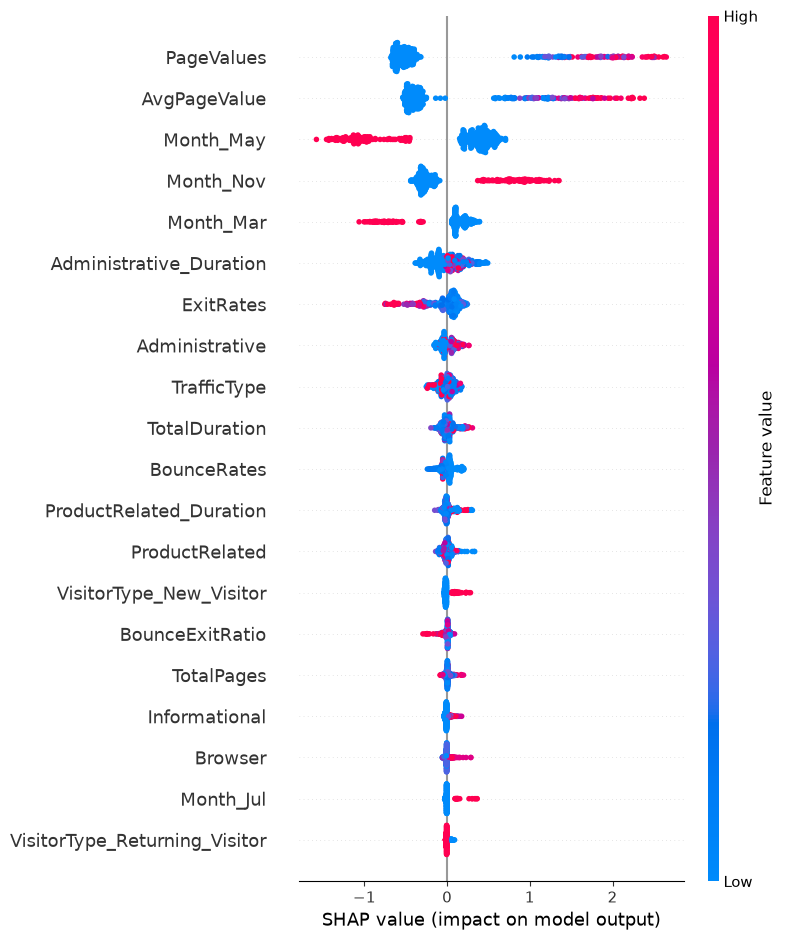

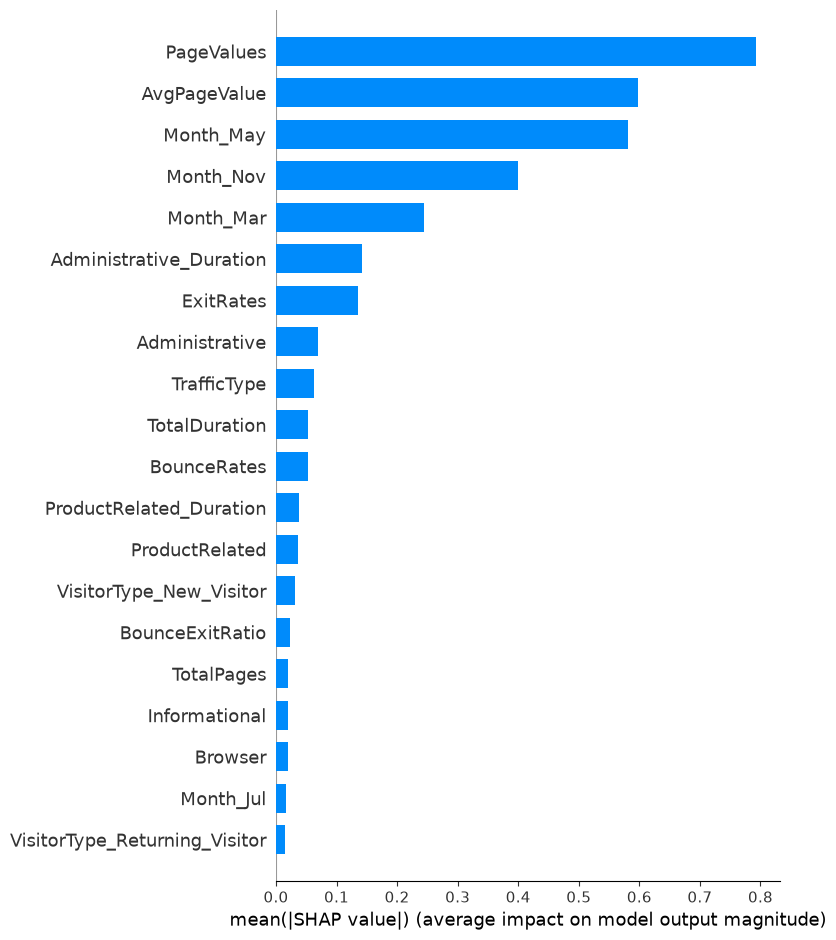

Индекс тестовой сессии: 6027
Вероятность покупки: 0.9716


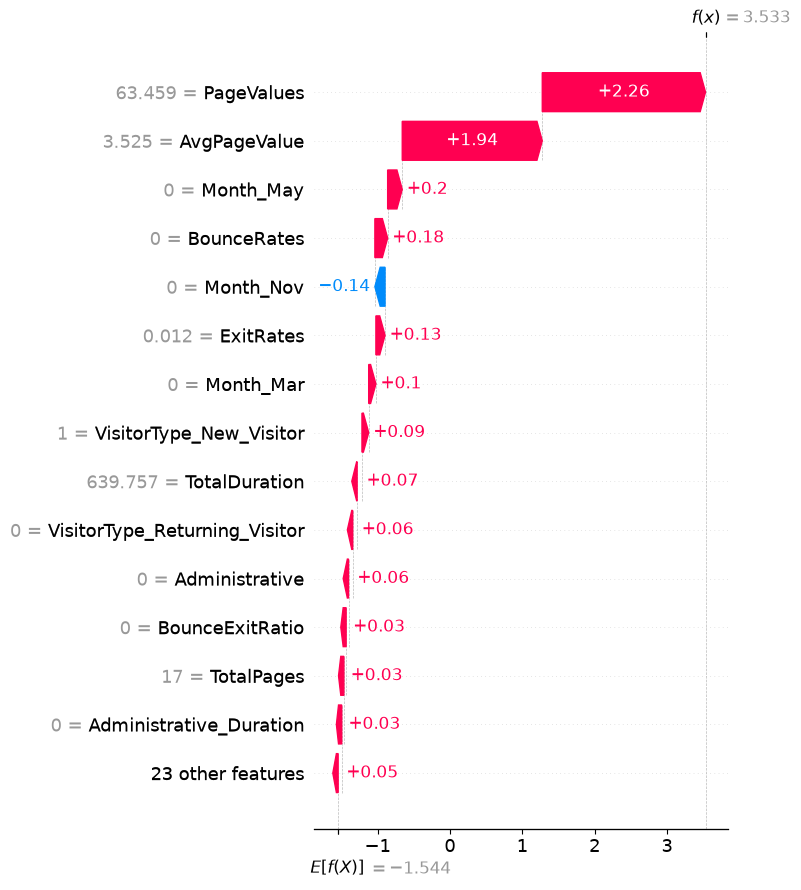

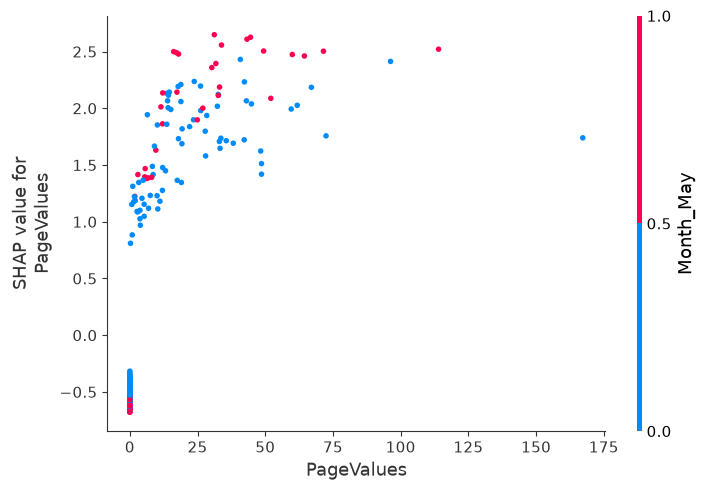

In [8]:
# Импортируем SHAP и подготавливаем ограниченную выборку для объяснений
import shap                                        
shap_sample = X_test_enc.sample(n=min(500, len(X_test_enc)), random_state=RANDOM_STATE)                                     
explainer = shap.TreeExplainer(best_lgbm)                                           
raw_shap_values = explainer.shap_values(shap_sample)                                          

# Унифицируем формат бинарной классификации для разных версий SHAP
if isinstance(raw_shap_values, list):                                                    
    shap_values_positive = raw_shap_values[1]                           
else:                                                               
    shap_values_positive = raw_shap_values[:, :, 1] if getattr(raw_shap_values, "ndim", 0) == 3 else raw_shap_values                                                         

# Строим глобальный summary plot и сохраняем его
shap.summary_plot(shap_values_positive, shap_sample, plot_type="dot", show=False)                                                 
plt.tight_layout()                                       
plt.savefig(EXAMPLES_DIR / "shap_summary.png", dpi=150, bbox_inches="tight")                           
plt.show()                            

# Строим bar plot глобальной важности SHAP
shap.summary_plot(shap_values_positive, shap_sample, plot_type="bar", show=False)                                       
plt.tight_layout()                        
plt.show()                        

# Находим сессию с наибольшей вероятностью покупки среди тестовых объектов
test_probabilities = best_lgbm.predict_proba(X_test_enc)[:, 1]                                  
best_idx = int(np.argmax(test_probabilities))                                               
best_row = X_test_enc.iloc[[best_idx]]                                             
single_shap_raw = explainer.shap_values(best_row)                                      
if isinstance(single_shap_raw, list):                                       
    single_shap = single_shap_raw[1][0]                                  
else:                                  
    single_shap = single_shap_raw[0, :, 1] if getattr(single_shap_raw, "ndim", 0) == 3 else single_shap_raw[0]                             
expected_value = explainer.expected_value                                     
if isinstance(expected_value, (list, np.ndarray)):                                             
    base_value = float(np.asarray(expected_value).reshape(-1)[-1])                                         
else:                            
    base_value = float(expected_value)                              
print(f"Индекс тестовой сессии: {X_test_enc.index[best_idx]}")                             
print(f"Вероятность покупки: {test_probabilities[best_idx]:.4f}")                        
waterfall_exp = shap.Explanation(values=single_shap, base_values=base_value, data=best_row.iloc[0].to_numpy(), feature_names=feature_cols)                              
shap.plots.waterfall(waterfall_exp, max_display=15, show=False)                                          
plt.tight_layout()                       
plt.savefig(EXAMPLES_DIR / "shap_waterfall.png", dpi=150, bbox_inches="tight")                             
plt.show()                              

# Строим dependence plot для признака с наибольшей средней абсолютной SHAP-важностью
mean_abs_shap = np.abs(shap_values_positive).mean(axis=0)                                          
top_shap_feature = feature_cols[int(np.argmax(mean_abs_shap))]                                 
shap.dependence_plot(top_shap_feature, shap_values_positive, shap_sample, show=False)                                                     
plt.tight_layout()                                
plt.show()                               

**Вывод по разделу.** SHAP-графики объясняют глобальные закономерности и отдельное предсказание оптимизированного LightGBM. Они помогают сформировать проверяемые бизнес-гипотезы, но не заменяют A/B-тесты и не доказывают причинность.

## 11. Сохранение модели и метаданных

Сохраняются четыре базовые модели, оптимизированный LightGBM, препроцессор, список признаков и метрики в формате JSON. Отдельное сохранение препроцессора нужно, чтобы при новых предсказаниях категории кодировались в том же порядке и числовые пропуски обрабатывались так же, как при обучении.

Файлы создаются в `models/`. Метрики сохраняются как числа, а не строки, чтобы их можно было повторно загружать и использовать для анализа. Графики EDA, Feature Importance и SHAP сохраняются в `examples/`.

In [9]:
# Импортируем joblib и сохраняем обученные объекты
import joblib                                            
joblib.dump(preprocessor, MODEL_DIR / "preprocessor.pkl")                                        
joblib.dump(models["Random Forest"], MODEL_DIR / "rf_model.pkl")                            
joblib.dump(models["XGBoost"], MODEL_DIR / "xgb_model.pkl")                      
joblib.dump(models["LightGBM"], MODEL_DIR / "lgbm_model.pkl")                               
joblib.dump(models["CatBoost"], MODEL_DIR / "cat_model.pkl")                       
joblib.dump(best_lgbm, MODEL_DIR / "best_model.pkl")                                  

with open(MODEL_DIR / "feature_cols.json", "w", encoding="utf-8") as file:                                        
    json.dump(feature_cols, file, ensure_ascii=False, indent=2)                                            
metrics_payload = {                                                  
    "baseline_models": results,                                    
    "training_times_seconds": training_times,                                   
    "best_baseline_model": best_baseline_name,                                   
    "best_lgbm_optuna_test_roc_auc": float(tuned_auc),                                  
    "baseline_lgbm_test_roc_auc": float(baseline_auc),                                       
    "best_lgbm_optuna_cv_roc_auc": float(study.best_value),                              
    "best_params": study.best_params,                        
    "feature_count_after_encoding": len(feature_cols)                                              
}
with open(MODEL_DIR / "metrics.json", "w", encoding="utf-8") as file:                              
    json.dump(metrics_payload, file, ensure_ascii=False, indent=2)                             
print(f"Модели и метаданные сохранены в {MODEL_DIR.resolve()}")                                 

Модели и метаданные сохранены в E:\Electiv1\module-4-features\models


**Вывод по разделу.** Модели и метаданные сохранены в `models/`. Вместе с моделью сохранён препроцессор и порядок признаков, поэтому артефакты можно использовать для воспроизводимого прогнозирования.

## 12. Загрузка модели из репозитория

Код загружает модель, список признаков и препроцессор по raw-ссылкам, проверяет HTTP-статусы и затем сравнивает предсказания на трёх тестовых сессиях.

In [10]:
BASE_URL = "https://raw.githubusercontent.com/ZhdanovaAnna/ml-course-zhdanova/main/module-4-features"                                                        
if "USERNAME/REPOSITORY" not in BASE_URL:                                                                
    import requests                                     
    from io import BytesIO                            
    model_response = requests.get(f"{BASE_URL}/models/best_model.pkl", timeout=30)                                       
    model_response.raise_for_status()                               
    loaded_model = joblib.load(BytesIO(model_response.content))                               
    features_response = requests.get(f"{BASE_URL}/models/feature_cols.json", timeout=30)                                 
    features_response.raise_for_status()                          
    loaded_features = features_response.json()                            
    loaded_preprocessor_response = requests.get(f"{BASE_URL}/models/preprocessor.pkl", timeout=30)                             
    loaded_preprocessor_response.raise_for_status()                                        
    loaded_preprocessor = joblib.load(BytesIO(loaded_preprocessor_response.content))                           
    print(f"Загружено признаков: {len(loaded_features)}")                            
else:                                                                        
    loaded_model = joblib.load(MODEL_DIR / "best_model.pkl")                                    
    loaded_features = json.loads((MODEL_DIR / "feature_cols.json").read_text(encoding="utf-8"))                            
    loaded_preprocessor = joblib.load(MODEL_DIR / "preprocessor.pkl")                           
    print("BASE_URL не настроен: выполнена локальная загрузка модели.")                                 

# Проверяем совпадение предсказаний оригинальной и повторно загруженной модели на трёх сессиях
sample_raw = X_test.iloc[:3]                                       
sample_encoded = loaded_preprocessor.transform(sample_raw)                                           
sample_encoded = pd.DataFrame(sample_encoded, columns=loaded_features, index=sample_raw.index)                                                 
pred_loaded = loaded_model.predict(sample_encoded)                                             
pred_original = best_lgbm.predict(X_test_enc.iloc[:3])                                                
print("Загруженная модель:", pred_loaded)                                  
print("Исходная модель:   ", pred_original)                                  
print("Предсказания совпадают:", bool(np.array_equal(pred_loaded, pred_original)))                                   

Загружено признаков: 37
Загруженная модель: [0 0 0]
Исходная модель:    [0 0 0]
Предсказания совпадают: True


**Вывод по разделу.** Проверка сравнивает результаты модели после повторной загрузки с исходными предсказаниями на трёх сессиях. 

## 13. Выводы

### Что получилось
После выполнения ноутбука заполните выводы фактическими значениями из таблиц: лучшая baseline-модель по ROC-AUC, её Accuracy/Precision/Recall/F1/ROC-AUC, тестовый ROC-AUC LightGBM после Optuna и разница с baseline. ТОП признаков следует брать из Feature Importance и SHAP-графиков.

### Трудности
1. Дисбаланс классов: положительный класс составляет около 15,5%, поэтому одной Accuracy недостаточно.

2. Категориальные переменные нужно кодировать одинаково для обучения и предсказания.

3. Подбор гиперпараметров требует вычислительных ресурсов; тестовую выборку нельзя использовать для настройки.

4. `PageValues` может содержать информацию, близкую к целевой; при внедрении нужно проверить доступность признака в момент прогнозирования.

### Возможные улучшения
1. Проверить качество без `PageValues`, чтобы оценить риск утечки целевой информации.

2. Добавить взаимодействия признаков, например `PageValues × TotalDuration`.

3. Сравнить One-Hot Encoding с Target Encoding внутри корректного CV-пайплайна.

4. Проверить SMOTE или другие методы балансировки только внутри тренировочных фолдов.

5. Выполнить калибровку вероятностей и подобрать бизнес-порог классификации.

6. Использовать временное разделение, если в дальнейшем появятся временные метки.

7. Настроить мониторинг дрейфа данных и версионирование признаков через Feature Store.

## 14. Источники и приложение

### Источники

1. Sakar, C. O., Polat, S. O., Katircioglu, M., Kastro, Y. (2019). *Real-time prediction of online shoppers’ purchasing intention using multilayer perceptron and LSTM recurrent neural networks*. Neural Computing and Applications, 31, 6893–6908. https://doi.org/10.1007/s00521-018-3523-0

2. UCI Machine Learning Repository. *Online Shoppers Purchasing Intention Dataset*. https://doi.org/10.24432/C5F88Q

3. Breiman, L. (2001). Random Forests. *Machine Learning*, 45, 5–32. https://doi.org/10.1023/A:1010933404324

4. Chen, T., Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System. *Proceedings of KDD ’16*. https://doi.org/10.1145/2939672.2939785

5. Ke, G. et al. (2017). LightGBM: A Highly Efficient Gradient Boosting Decision Tree. *NeurIPS 2017*.

6. Prokhorenkova, L. et al. (2018). CatBoost: unbiased boosting with categorical features. *NeurIPS 2018*.

7. Lundberg, S. M., Lee, S.-I. (2017). A Unified Approach to Interpreting Model Predictions. *NeurIPS 2017*.

8. Akiba, T. et al. (2019). Optuna: A Next-generation Hyperparameter Optimization Framework. *Proceedings of KDD ’19*.

### Приложение: requirements.txt и полный код в jupytext

**Файл requirements.txt:**

pandas>=2.0   
numpy>=1.24   
scikit-learn>=1.3   
xgboost>=2.0   
lightgbm>=4.0   
catboost>=1.2   
optuna>=3.5   
shap>=0.44   
matplotlib>=3.7   
seaborn>=0.12   
joblib>=1.3   
requests>=2.31   
jupyter>=1.0   


**Полный код**
```Python
# %%
# Импортируем библиотеки для загрузки, анализа, визуализации и моделирования
from pathlib import Path                                   
import time                               
import json                                 
import warnings                                                
warnings.filterwarnings("ignore")                                                                   

import numpy as np                         
import pandas as pd                     
import matplotlib.pyplot as plt                        
import seaborn as sns                                

RANDOM_STATE = 42                                         
DATA_DIR = Path("data")                                          
MODEL_DIR = Path("models")                                           
EXAMPLES_DIR = Path("examples")                       
DATA_DIR.mkdir(parents=True, exist_ok=True)                                           
MODEL_DIR.mkdir(parents=True, exist_ok=True)                                            
EXAMPLES_DIR.mkdir(parents=True, exist_ok=True)    

# %% 
# Загрузка датасета и описнаие данных
data_path = DATA_DIR / "online_shoppers_intention.csv"                                       

df = pd.read_csv(data_path)                               

# Проверка пропусков и нулевых значений
print(f"Размер датасета: {df.shape[0]} строк × {df.shape[1]} столбцов")   
print("Количество пропусков:", df.isna().sum().sum())
print("\nКоличество дубликатов:", df.duplicated().sum())

zero_counts = (df == 0).sum().sort_values(ascending=False)
print("\nКоличество нулевых значений по столбцам:")
display(zero_counts.to_frame("Количество нулей"))

display(df.head())                             
display(df.dtypes.rename("Тип данных").to_frame())                            
print("\nПропуски по столбцам:")                               
display(df.isna().sum().sort_values(ascending=False).rename("Количество пропусков").to_frame())                       
print("\nРаспределение Revenue:")                                    
display(pd.DataFrame({"Количество": df["Revenue"].value_counts(), "Доля": df["Revenue"].value_counts(normalize=True).round(4)}))               

# %% 
# Приводим целевую переменную к 0/1 и проверяем повторы до дальнейших преобразований
df["Revenue"] = df["Revenue"].astype(int)                                                 
duplicate_count = int(df.duplicated().sum())                             
print(f"Полных дубликатов: {duplicate_count}")                             
df = df.drop_duplicates().copy()                                                                     

# Заполняем пропуски консервативно: числовые  медианой, категориальные - модой
for col in df.columns:                                         
    if df[col].isna().any():                                             
        if pd.api.types.is_numeric_dtype(df[col]):                            
            df[col] = df[col].fillna(df[col].median())                                         
        else:                                                                  
            df[col] = df[col].fillna(df[col].mode(dropna=True).iloc[0])                             

# Создаём агрегаты сессии, отражающие глубину просмотра и вовлечённость
df["TotalPages"] = df["Administrative"] + df["Informational"] + df["ProductRelated"]                        
df["TotalDuration"] = df["Administrative_Duration"] + df["Informational_Duration"] + df["ProductRelated_Duration"]                           
df["AvgPageValue"] = df["PageValues"] / (df["TotalPages"] + 1)                                                         
df["BounceExitRatio"] = df["BounceRates"] / (df["ExitRates"] + 0.001)                                                  
df["IsNewVisitor"] = (df["VisitorType"] == "New_Visitor").astype(int)                                
df["IsWeekend"] = df["Weekend"].astype(int)                                     
df["MonthNum"] = pd.to_datetime(df["Month"], format="%b", errors="coerce").dt.month                                        
df["MonthNum"] = df["MonthNum"].fillna(0).astype(int)                                                          
df["IsHighTraffic"] = (df["TrafficType"] > 10).astype(int)                                                     

# Печатаем краткую статистику, чтобы результаты можно было перенести в отчёт
print(f"Размер после очистки: {df.shape}")                                               
print(f"Число признаков после Feature Engineering (без Revenue): {df.drop(columns='Revenue').shape[1]}")                             
display(df[["TotalPages", "TotalDuration", "AvgPageValue", "BounceExitRatio", "IsNewVisitor", "MonthNum", "IsHighTraffic"]].describe().T)                                            

# Строим сетку из шести подписанных графиков EDA
fig, axes = plt.subplots(2, 3, figsize=(18, 10))                      
sns.countplot(data=df, x="Revenue", ax=axes[0, 0])                                      
axes[0, 0].set_title("Распределение Revenue")                              
sns.histplot(data=df, x="TotalDuration", hue="Revenue", bins=40, element="step", stat="density", common_norm=False, ax=axes[0, 1])                                              
axes[0, 1].set_title("Суммарная длительность сессии")                              
sns.boxplot(data=df, x="Revenue", y="PageValues", ax=axes[0, 2])                                         
axes[0, 2].set_title("PageValues по целевому классу")                              
sns.countplot(data=df, x="VisitorType", hue="Revenue", ax=axes[1, 0])                                            
axes[1, 0].set_title("Покупки по типу посетителя")                                 
sns.boxplot(data=df, x="Revenue", y="BounceRates", ax=axes[1, 1])                                  
axes[1, 1].set_title("BounceRates по целевому классу")                             
month_order = ["Feb", "Mar", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]                                                       
sns.countplot(data=df, x="Month", hue="Revenue", order=[m for m in month_order if m in set(df["Month"])], ax=axes[1, 2])                                               
axes[1, 2].set_title("Сессии и покупки по месяцам")                              
for ax in axes.flat:                              
    ax.set_xlabel(ax.get_xlabel() or "Значение")                                
    ax.set_ylabel(ax.get_ylabel() or "Количество")                                
    ax.tick_params(axis="x", rotation=25)                                        
plt.tight_layout()                                
plt.savefig(EXAMPLES_DIR / "eda_plots.png", dpi=150, bbox_inches="tight")                          
plt.show()                            

# %% 
# Импортируем алгоритмы и инструменты разделения данных
from sklearn.model_selection import train_test_split                                             
from sklearn.preprocessing import OneHotEncoder                                         
from sklearn.compose import ColumnTransformer                                         
from sklearn.pipeline import Pipeline                                        
from sklearn.impute import SimpleImputer                                    
from sklearn.ensemble import RandomForestClassifier                     
from xgboost import XGBClassifier                                
from lightgbm import LGBMClassifier                                 
from catboost import CatBoostClassifier                                 

# Разделяем признаки и целевую переменную; Revenue не попадает во входные данные
X = df.drop(columns=["Revenue"]).copy()                                           
y = df["Revenue"].astype(int).copy()                          
categorical_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()                                      
numeric_cols = [col for col in X.columns if col not in categorical_cols]                                        
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)                                           

# Обучаем преобразователь только на train, чтобы не подглядывать в тестовую выборку
try:                                                  
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)                                          
except TypeError:                                                                 
    encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)                                     
preprocessor = ColumnTransformer([("cat", encoder, categorical_cols), ("num", SimpleImputer(strategy="median"), numeric_cols)], remainder="drop", verbose_feature_names_out=False)                                     
X_train_enc = preprocessor.fit_transform(X_train)                                                      
X_test_enc = preprocessor.transform(X_test)                                                  
feature_cols = preprocessor.get_feature_names_out().tolist()                                                       
X_train_enc = pd.DataFrame(X_train_enc, columns=feature_cols, index=X_train.index)                                                
X_test_enc = pd.DataFrame(X_test_enc, columns=feature_cols, index=X_test.index)                                        

# Считаем вес положительного класса из train, а не задаём его вручную
negative_count = int((y_train == 0).sum())                                     
positive_count = int((y_train == 1).sum())                                    
positive_weight = negative_count / max(positive_count, 1)                                  

models = {                                                             
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=10, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),                             
    "XGBoost": XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1, subsample=0.9, colsample_bytree=0.9, scale_pos_weight=positive_weight, random_state=RANDOM_STATE, eval_metric="logloss", n_jobs=-1),                                       
    "LightGBM": LGBMClassifier(n_estimators=200, num_leaves=31, max_depth=7, learning_rate=0.05, class_weight="balanced", random_state=RANDOM_STATE, verbosity=-1, n_jobs=-1),                                     
    "CatBoost": CatBoostClassifier(iterations=200, depth=6, learning_rate=0.1, auto_class_weights="Balanced", random_seed=RANDOM_STATE, verbose=False, thread_count=-1)                                              
}
training_times = {}                                 
for name, model in models.items():                              
    start_time = time.time()                              
    model.fit(X_train_enc, y_train)                                                        
    training_times[name] = time.time() - start_time                                    
    print(f"{name}: время обучения {training_times[name]:.3f} сек.")                           

# %% 
# Импортируем метрики и инструменты визуализации качества
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report, RocCurveDisplay                          
from sklearn.metrics import ConfusionMatrixDisplay                               

def evaluate_model(model, X_eval, y_eval, name):                                 
    y_pred = model.predict(X_eval)                                    
    y_proba = model.predict_proba(X_eval)[:, 1]                                               
    return {"Model": name, "Accuracy": accuracy_score(y_eval, y_pred), "Precision": precision_score(y_eval, y_pred, zero_division=0), "Recall": recall_score(y_eval, y_pred, zero_division=0), "F1": f1_score(y_eval, y_pred, zero_division=0), "ROC-AUC": roc_auc_score(y_eval, y_proba)}                                        

results = [evaluate_model(model, X_test_enc, y_test, name) for name, model in models.items()]                                          
results_df = pd.DataFrame(results).sort_values("ROC-AUC", ascending=False).reset_index(drop=True)                         
results_df["Training time, sec"] = results_df["Model"].map(training_times)                                       
display(results_df.round(4))                                        

best_baseline_name = results_df.iloc[0]["Model"]                                               
best_baseline = models[best_baseline_name]                                  
best_pred = best_baseline.predict(X_test_enc)                                            
fig, ax = plt.subplots(figsize=(5, 4))                                       
ConfusionMatrixDisplay.from_predictions(y_test, best_pred, display_labels=["Нет покупки", "Покупка"], cmap="Blues", ax=ax, colorbar=False)                                                 
ax.set_title(f"Матрица ошибок: {best_baseline_name}")                        
plt.tight_layout()                                   
plt.show()                              

fig, ax = plt.subplots(figsize=(8, 6))                               
for name, model in models.items():                                           
    RocCurveDisplay.from_estimator(model, X_test_enc, y_test, name=name, ax=ax)                            
ax.plot([0, 1], [0, 1], linestyle="--", label="Случайный классификатор")                                    
ax.set_title("ROC-кривые ансамблевых моделей")                       
plt.tight_layout()                     
plt.savefig(EXAMPLES_DIR / "roc_curves.png", dpi=150, bbox_inches="tight")                         
plt.show()                          

print(f"Лучшая baseline-модель по ROC-AUC: {best_baseline_name}")                                   
print(classification_report(y_test, best_pred, target_names=["Нет покупки", "Покупка"], zero_division=0))                                          

# %%
# Строим таблицы важности для Random Forest и LightGBM
importance_tables = {}                                                
for model_name in ["Random Forest", "LightGBM"]:                                                              
    importance_tables[model_name] = pd.DataFrame({"Feature": feature_cols, "Importance": models[model_name].feature_importances_}).sort_values("Importance", ascending=False)                                           
    print(f"15 признаков: {model_name}")                               
    display(importance_tables[model_name].head(15).round(5))                                                 

# Визуализируем важность LightGBM и сохраняем график
top_lgbm = importance_tables["LightGBM"].head(15).sort_values("Importance", ascending=True)                                           
fig, ax = plt.subplots(figsize=(9, 6))                   
sns.barplot(data=top_lgbm, x="Importance", y="Feature", ax=ax)                              
ax.set_title("15 важных признаков (LightGBM)")                       
ax.set_xlabel("Важность признака")                      
ax.set_ylabel("Признак")                      
plt.tight_layout()                     
plt.savefig(EXAMPLES_DIR / "feature_importance.png", dpi=150, bbox_inches="tight")                              
plt.show()                      

# Формируем нейтральные бизнес-инсайты на основании полученного ранжирования
top5_features = importance_tables["LightGBM"]["Feature"].head(5).tolist()                                         
print("5 признаков LightGBM:", ", ".join(top5_features))                                
print("Бизнес-интерпретация: использовать эти признаки для анализа вовлечённости и сегментации сессий; направление влияния проверить SHAP-графиками.")                                                    

# %%
# Импортируем Optuna и средства стратифицированной кросс-валидации
import optuna                                            
from sklearn.model_selection import StratifiedKFold, cross_val_score                                           

optuna.logging.set_verbosity(optuna.logging.WARNING)                                     
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)                                        

def objective(trial):                                                          
    params = {                                 
        "n_estimators": trial.suggest_int("n_estimators", 100, 500, step=50),                   
        "num_leaves": trial.suggest_int("num_leaves", 10, 100, step=5),                  
        "max_depth": trial.suggest_int("max_depth", 3, 12),                         
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),                      
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),                              
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),                             
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 50),                             
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10, log=True),                     
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True)                     
    }
    candidate = LGBMClassifier(**params, class_weight="balanced", random_state=RANDOM_STATE, verbosity=-1, n_jobs=-1)                            
    scores = cross_val_score(candidate, X_train_enc, y_train, cv=cv, scoring="roc_auc", n_jobs=1)                                            
    return float(scores.mean())                               

study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))                                   
study.optimize(objective, n_trials=30, show_progress_bar=True)                          
print(f"Лучший CV ROC-AUC: {study.best_value:.4f}")                               
print("Лучшие параметры:")                         
for key, value in study.best_params.items():                                   
    print(f"  {key}: {value}")                               

best_lgbm = LGBMClassifier(**study.best_params, class_weight="balanced", random_state=RANDOM_STATE, verbosity=-1, n_jobs=-1)                          
start_time = time.time()                                            
best_lgbm.fit(X_train_enc, y_train)                                          
best_lgbm_time = time.time() - start_time                             
baseline_auc = roc_auc_score(y_test, models["LightGBM"].predict_proba(X_test_enc)[:, 1])                                       
tuned_auc = roc_auc_score(y_test, best_lgbm.predict_proba(X_test_enc)[:, 1])                                    
print(f"ROC-AUC LightGBM baseline (test): {baseline_auc:.4f}")                                
print(f"ROC-AUC LightGBM Optuna (test):   {tuned_auc:.4f}")                                         
print(f"Изменение ROC-AUC: {tuned_auc - baseline_auc:+.4f}")                                            

# %% 
# Импортируем SHAP и подготавливаем ограниченную выборку для объяснений
import shap                                        
shap_sample = X_test_enc.sample(n=min(500, len(X_test_enc)), random_state=RANDOM_STATE)                                     
explainer = shap.TreeExplainer(best_lgbm)                                           
raw_shap_values = explainer.shap_values(shap_sample)                                          

# Унифицируем формат бинарной классификации для разных версий SHAP
if isinstance(raw_shap_values, list):                                                    
    shap_values_positive = raw_shap_values[1]                           
else:                                                               
    shap_values_positive = raw_shap_values[:, :, 1] if getattr(raw_shap_values, "ndim", 0) == 3 else raw_shap_values                                                         

# Строим глобальный summary plot и сохраняем его
shap.summary_plot(shap_values_positive, shap_sample, plot_type="dot", show=False)                                                 
plt.tight_layout()                                       
plt.savefig(EXAMPLES_DIR / "shap_summary.png", dpi=150, bbox_inches="tight")                           
plt.show()                            

# Строим bar plot глобальной важности SHAP
shap.summary_plot(shap_values_positive, shap_sample, plot_type="bar", show=False)                                       
plt.tight_layout()                        
plt.show()                        

# Находим сессию с наибольшей вероятностью покупки среди тестовых объектов
test_probabilities = best_lgbm.predict_proba(X_test_enc)[:, 1]                                  
best_idx = int(np.argmax(test_probabilities))                                               
best_row = X_test_enc.iloc[[best_idx]]                                             
single_shap_raw = explainer.shap_values(best_row)                                      
if isinstance(single_shap_raw, list):                                       
    single_shap = single_shap_raw[1][0]                                  
else:                                  
    single_shap = single_shap_raw[0, :, 1] if getattr(single_shap_raw, "ndim", 0) == 3 else single_shap_raw[0]                             
expected_value = explainer.expected_value                                     
if isinstance(expected_value, (list, np.ndarray)):                                             
    base_value = float(np.asarray(expected_value).reshape(-1)[-1])                                         
else:                            
    base_value = float(expected_value)                              
print(f"Индекс тестовой сессии: {X_test_enc.index[best_idx]}")                             
print(f"Вероятность покупки: {test_probabilities[best_idx]:.4f}")                        
waterfall_exp = shap.Explanation(values=single_shap, base_values=base_value, data=best_row.iloc[0].to_numpy(), feature_names=feature_cols)                              
shap.plots.waterfall(waterfall_exp, max_display=15, show=False)                                          
plt.tight_layout()                       
plt.savefig(EXAMPLES_DIR / "shap_waterfall.png", dpi=150, bbox_inches="tight")                             
plt.show()                              

# Строим dependence plot для признака с наибольшей средней абсолютной SHAP-важностью
mean_abs_shap = np.abs(shap_values_positive).mean(axis=0)                                          
top_shap_feature = feature_cols[int(np.argmax(mean_abs_shap))]                                 
shap.dependence_plot(top_shap_feature, shap_values_positive, shap_sample, show=False)                                                     
plt.tight_layout()                                
plt.show()                               

# %%
# Импортируем joblib и сохраняем обученные объекты
import joblib                                            
joblib.dump(preprocessor, MODEL_DIR / "preprocessor.pkl")                                        
joblib.dump(models["Random Forest"], MODEL_DIR / "rf_model.pkl")                            
joblib.dump(models["XGBoost"], MODEL_DIR / "xgb_model.pkl")                      
joblib.dump(models["LightGBM"], MODEL_DIR / "lgbm_model.pkl")                               
joblib.dump(models["CatBoost"], MODEL_DIR / "cat_model.pkl")                       
joblib.dump(best_lgbm, MODEL_DIR / "best_model.pkl")                                  

with open(MODEL_DIR / "feature_cols.json", "w", encoding="utf-8") as file:                                        
    json.dump(feature_cols, file, ensure_ascii=False, indent=2)                                            
metrics_payload = {                                                  
    "baseline_models": results,                                    
    "training_times_seconds": training_times,                                   
    "best_baseline_model": best_baseline_name,                                   
    "best_lgbm_optuna_test_roc_auc": float(tuned_auc),                                  
    "baseline_lgbm_test_roc_auc": float(baseline_auc),                                       
    "best_lgbm_optuna_cv_roc_auc": float(study.best_value),                              
    "best_params": study.best_params,                        
    "feature_count_after_encoding": len(feature_cols)                                              
}
with open(MODEL_DIR / "metrics.json", "w", encoding="utf-8") as file:                              
    json.dump(metrics_payload, file, ensure_ascii=False, indent=2)                             
print(f"Модели и метаданные сохранены в {MODEL_DIR.resolve()}")                                 

# %%
BASE_URL = "https://raw.githubusercontent.com/ZhdanovaAnna/ml-course-zhdanova/main/module-4-features"                                                        
if "USERNAME/REPOSITORY" not in BASE_URL:                                                                
    import requests                                     
    from io import BytesIO                            
    model_response = requests.get(f"{BASE_URL}/models/best_model.pkl", timeout=30)                                       
    model_response.raise_for_status()                               
    loaded_model = joblib.load(BytesIO(model_response.content))                               
    features_response = requests.get(f"{BASE_URL}/models/feature_cols.json", timeout=30)                                 
    features_response.raise_for_status()                          
    loaded_features = features_response.json()                            
    loaded_preprocessor_response = requests.get(f"{BASE_URL}/models/preprocessor.pkl", timeout=30)                             
    loaded_preprocessor_response.raise_for_status()                                        
    loaded_preprocessor = joblib.load(BytesIO(loaded_preprocessor_response.content))                           
    print(f"Загружено признаков: {len(loaded_features)}")                            
else:                                                                        
    loaded_model = joblib.load(MODEL_DIR / "best_model.pkl")                                    
    loaded_features = json.loads((MODEL_DIR / "feature_cols.json").read_text(encoding="utf-8"))                            
    loaded_preprocessor = joblib.load(MODEL_DIR / "preprocessor.pkl")                           
    print("BASE_URL не настроен: выполнена локальная загрузка модели.")                                 

# Проверяем совпадение предсказаний оригинальной и повторно загруженной модели на трёх сессиях
sample_raw = X_test.iloc[:3]                                       
sample_encoded = loaded_preprocessor.transform(sample_raw)                                           
sample_encoded = pd.DataFrame(sample_encoded, columns=loaded_features, index=sample_raw.index)                                                 
pred_loaded = loaded_model.predict(sample_encoded)                                             
pred_original = best_lgbm.predict(X_test_enc.iloc[:3])                                                
print("Загруженная модель:", pred_loaded)                                  
print("Исходная модель:   ", pred_original)                                  
print("Предсказания совпадают:", bool(np.array_equal(pred_loaded, pred_original)))              
```         